In [1]:
import pandas as pd
import numpy as np
import umap
import joblib
from pathlib import Path
import os
import glob

In [2]:
OVERWRITE = False
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)

In [11]:
# files obtained from Austin Oleski and uploaded to Dropbox for easy access; 
# all files can be downloaded as a single zip file and extracted
# these files have been added to the .gitignore for this repo so they will not be tracked
zip_files_url = "https://www.dropbox.com/sh/q5lz0fxkodif7ao/AAALIBublRcHoCf7yQ56tsCea?dl=1"

if not os.path.exists(Path("extracted_files/")):
    import requests
    import zipfile

    # send a GET request to the URL and download the content
    response = requests.get(zip_files_url)

    # save the content to a local file
    with open("temp.zip", "wb") as f:
        f.write(response.content)

    # extract the files from the zip archive
    with zipfile.ZipFile("temp.zip", "r") as zip_ref:
        zip_ref.extractall("extracted_files")

# get a list of all the filenames in the extracted_files directory
filenames = []

for root, dirs, files in os.walk("extracted_files"):
    for file in files:
        filenames.append(os.path.join(root, file))

# print the list of filenames
print(filenames)


['extracted_files\\dmso_long_4_29_1_1.txt', 'extracted_files\\dmso_long_4_29_2_1.txt', 'extracted_files\\dmso_long_4_29_3_1.txt', 'extracted_files\\erl_long_4_29_1_1.txt', 'extracted_files\\erl_long_4_29_2_1.txt', 'extracted_files\\erl_long_4_29_3_1.txt']


### Setting to adjust umap density
#### Original values: 
* `init_dt = 0.01`
* `dt = 0.2`
* `window = 2`
* `time_step = 1`

#### umap params
* `neighbs = 50`
* `min_d = 0.05`


### Filenaming convention
Filename will incorporate parameter values in order above (not including umap parameters).

In [3]:
OVERWRITE = False
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)

In [4]:
order = [2, 0, 4, 3, 1, 5]
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output', 'stoch_sim*param_orig.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
filenames = [filenames[n] for n in order]
filenames

['C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_soft_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_int_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_soft_erl_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_int_erl_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff_erl_param_orig.csv']

In [5]:
order = [2, 0, 4, 3, 1, 5]
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output', 'ode_sim*param_orig.csv')
filenames_ode = glob.glob(file_location)
filenames_ode = sorted(filenames_ode)
filenames_ode = [filenames_ode[n] for n in order]
filenames_ode

['C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_soft_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_int_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_stiff_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_soft_erl_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_int_erl_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_stiff_erl_param_orig.csv']

In [22]:
#The filenames to make the reducer umap object from
"""
filenames = ['erl_4-9_1_1.txt', 'erl_4-9_2_1.txt', 'erl_4-9_3_1.txt',
             'dmso_4-9_1_1.txt', 'dmso_4-9_2_1.txt', 'dmso_4-9_3_1.txt']
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 5                    #window size in hours
time_step = 1                 #time step between windows

#umap params
neighbs = 100
min_d = 0.05
"""
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.05

#reducer save name
r_name = f'reducer_03_12_{init_dt}_{dt}_{window}_{time_step}.sav'

In [7]:
#Load and resample time based on umap window
# time_tmp = pd.read_csv('t_4-9_3_3.txt', sep=",", header=None)
# time_tmp = time_tmp.T
# time_tmp.columns = ["time"]
# time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [8]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\', 'stoch_sim*orig.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
# filenames_sp = [filenames[5], filenames[6], filenames[3], filenames[4], filenames[7], filenames[8], 
#                filenames[0], filenames[1], filenames[2]]

filenames_sp = [filenames[0], filenames[3], filenames[8],
                filenames[11], filenames[12], filenames[18], filenames[24]]

filenames_conds = [filenames[0], filenames[12], filenames[5],
                filenames[18], filenames[11], filenames[24]]

# filenames_conds = [filenames[0], filenames[5], filenames[11],
#                 filenames[12], filenames[18], filenames[24]]

# filenames_sp = [filenames[3], filenames[0], filenames[1], filenames[2],
#                 filenames[4], filenames[5], filenames[6], filenames[7]]
# filenames_sp=filenames

filenames_conds


['C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff099_orig.csv']

In [9]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\', 'ODE_sim*orig.csv')
filenames_ode = glob.glob(file_location)
filenames_ode = sorted(filenames_ode)
filenames_sp_ode = [filenames_ode[0], filenames_ode[3], filenames_ode[8],
                    filenames_ode[11], filenames_ode[12], filenames_ode[18], filenames_ode[25]]

filenames_conds_ode = [filenames_ode[0], filenames_ode[12], filenames_ode[5],
                    filenames_ode[18], filenames_ode[11], filenames_ode[25]]

# filenames_conds_ode = [filenames_ode[0], filenames_ode[5], filenames_ode[11],
#                     filenames_ode[12], filenames_ode[18], filenames_ode[25]]

# filenames_sp_ode = [filenames_ode[3], filenames_ode[0], filenames_ode[1], filenames_ode[2],
#                     filenames_ode[4], filenames_ode[5], filenames_ode[6], filenames_ode[7]]
#filenames_sp_ode = filenames_ode

filenames_conds_ode


['C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff099_orig.csv']

In [ ]:
# file_location = os.path.join('D:\\stoch_runs_230713\\', '*_orig_long.csv')
# filenames = glob.glob(file_location)
# filenames = sorted(filenames)
# filenames_sp = [filenames[3], filenames[2], filenames[1], filenames[5], filenames[0], filenames[4]]
# filenames_sp

In [51]:
######## old
def load_norm_data(filenames, time_file, init_dt, dt, window, time_step):
    time_tmp = pd.read_csv(time_file, sep=",", header=None)
    time_tmp = time_tmp.T
    time_tmp.columns = ["time"]
    time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
    
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp[prot_tmp<0] = 0
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames:
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])
        prot_tmp2 = prot_tmp.iloc[::int(dt//init_dt),:].reset_index().drop(columns=['index'])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
    return all_prot_tmp, all_time_tmp, all_time_at_tmp
        

In [10]:
def calc_minmax(filenames, filenames_ode):
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
        
    return max_prots, min_prots

In [11]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(SAVE_DIR + f"phaseplot_{num}.png", bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(SAVE_DIR + f"phaseplot_norm_{num}.png", bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [127]:
all_prot_tmp, all_time_tmp, all_time_at_tmp = load_norm_data(filenames, 't_4-9_3_3.txt', init_dt, dt, window, time_step)

TypeError: load_norm_data() missing 4 required positional arguments: 'dt', 'window', 'time_step', and 'plot_phase'

In [12]:
max_prots, min_prots = calc_minmax(filenames_conds, filenames_conds_ode)

In [13]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_conds, filenames_conds_ode, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [14]:
int(window/dt)

40

In [15]:
cond_len = int(len(all_prot_tmp)/6)
cond_len

39993

In [16]:
reducer = umap.UMAP(
        n_neighbors=neighbs,
        min_dist=min_d,
        n_components=2,
        metric='euclidean',
        random_state=5,
        low_memory=True        
        ).fit(all_prot_tmp)

embedding_all_prot = reducer.transform(all_prot_tmp)

In [17]:
import matplotlib.pyplot as plt

### Plot ERL trajectories

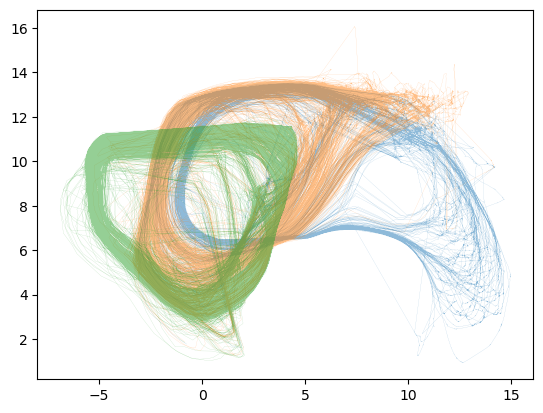

In [18]:
fig = plt.figure()
plt.plot(embedding_all_prot[1*cond_len:2*cond_len,0], embedding_all_prot[1*cond_len:2*cond_len,1], lw=0.1, alpha=0.5)
plt.plot(embedding_all_prot[3*cond_len:4*cond_len,0], embedding_all_prot[3*cond_len:4*cond_len,1], lw=0.1, alpha=0.5)
plt.plot(embedding_all_prot[5*cond_len:6*cond_len,0], embedding_all_prot[5*cond_len:6*cond_len,1], lw=0.1, alpha=0.5)


### Plot DMSO trajectories

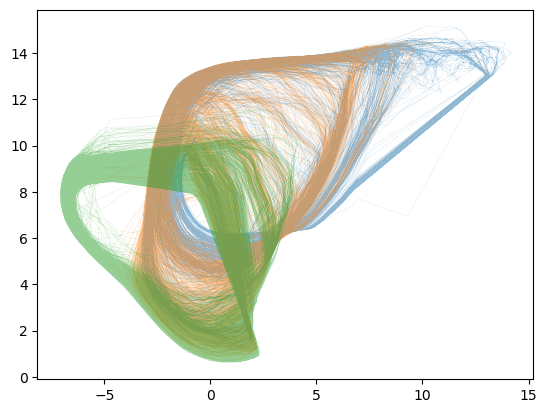

In [19]:
fig = plt.figure()
plt.plot(embedding_all_prot[0*cond_len:1*cond_len,0], embedding_all_prot[0*cond_len:1*cond_len,1], lw=0.1, alpha=0.5)
plt.plot(embedding_all_prot[2*cond_len:3*cond_len,0], embedding_all_prot[2*cond_len:3*cond_len,1], lw=0.1, alpha=0.5)
plt.plot(embedding_all_prot[4*cond_len:5*cond_len,0], embedding_all_prot[4*cond_len:5*cond_len,1], lw=0.1, alpha=0.5)


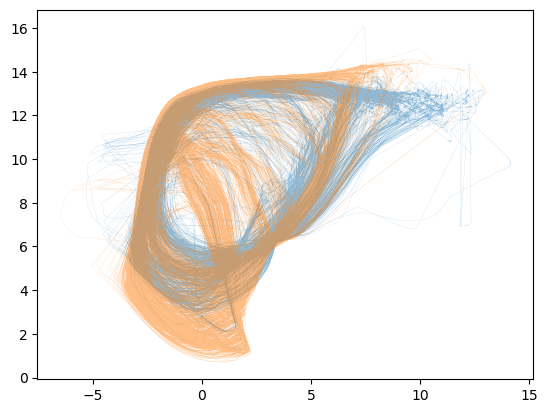

In [20]:
plt.plot(embedding_all_prot[3*cond_len:4*cond_len,0], embedding_all_prot[3*cond_len:4*cond_len,1], lw=0.1, alpha=0.5)
plt.plot(embedding_all_prot[2*cond_len:3*cond_len,0], embedding_all_prot[2*cond_len:3*cond_len,1], lw=0.1, alpha=0.5)


### Plot all trajectories

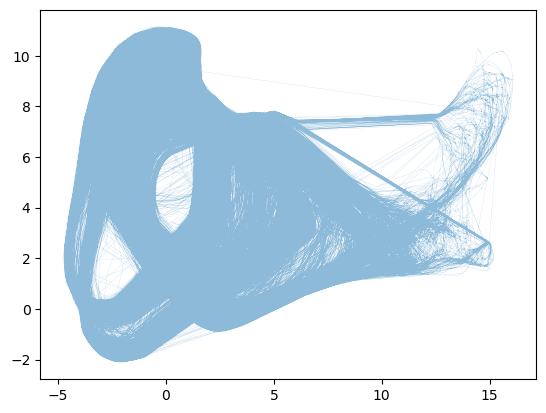

In [116]:
fig = plt.figure()
plt.plot(embedding_all_prot[:,0], embedding_all_prot[:,1], lw=0.1, alpha=0.5)

### Save reducer file
Large file (~1.5-2 GB). Will save in `SAVEDIR` if doesn't already exist or if `OVERWRITE = True`

In [23]:
reducer_filename = Path(SAVEDIR, r_name)
if not os.path.exists(reducer_filename) or OVERWRITE:
    joblib.dump(reducer, reducer_filename)

In [24]:
SAVEDIR

WindowsPath('C:/Users/olesk/ECM_mod_output')

### Plot example molecule levels

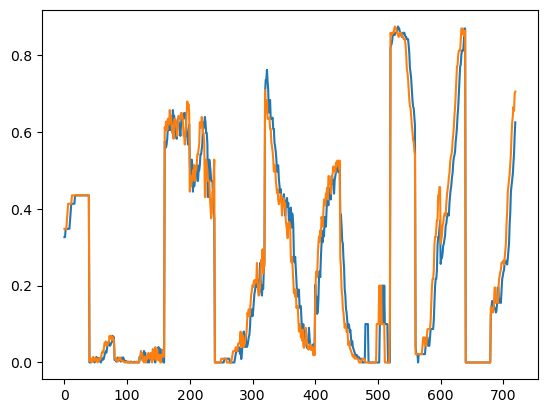

In [44]:
fig = plt.figure()
plt.plot(all_prot_tmp[10000,:])
plt.plot(all_prot_tmp[10001,:])

### Plot example umap embedding

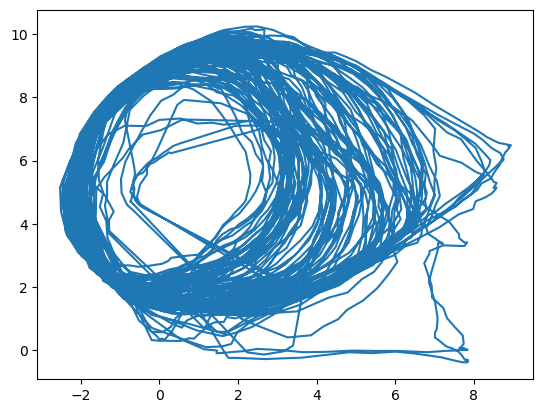

In [45]:
fig = plt.figure()
plt.plot(embedding_all_prot[:5000,0], embedding_all_prot[:5000,1])